# ViT-B/16 full fine-tune on Colab (GPU)

Goal: make the model look at the **hands**, not the signer. Private test (51% with a frozen ViT, vs 81% OOF) looks like it contains signers unseen in train.

- Backbone `vit_b_16` / `IMAGENET1K_V1`, **fully fine-tuned** (layer-wise LR decay, AMP, gradient checkpointing) + temporal Transformer head.
- Full 224×224 frames, **16 frames**; blank padding frames (in ~20% of train videos, almost never in test) are dropped before sampling.
- Strong clip-consistent augmentation, never cropping the borders: zoom-out/shift/rotate with padding, colour/hue/saturation jitter, grayscale, channel shuffle, Gaussian/salt-pepper noise, blur.
- Each epoch uses one random file per original video (`xxx.mp4`, `xxx_1.mp4`… are colour-jittered copies).
- Checkpoint every epoch to Drive → resumes automatically after a Colab disconnect.

**Setup**: upload `CV/dataset.zip` to Google Drive at `MyDrive/sign-language/dataset.zip`, pick a GPU runtime (T4 works, A100/L4 is ~3× faster).

In [1]:
!nvidia-smi
import torch; print(torch.__version__, torch.version.cuda, torch.cuda.is_available())

Fri Oct 23 04:30:30 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os, sys, re, time, math, pickle, random, zipfile, unicodedata

IN_COLAB = os.path.exists('/content')
DRIVE_DIR = '/content/drive/MyDrive/sign-language'   # used only if Drive can be mounted (not in the VS Code Colab extension)
# Share dataset.zip on Google Drive as "Anyone with the link" and paste the link (or just the file id) here:
DATASET_URL = 'https://drive.google.com/file/d/1Bg-PByokbKDAftvU6LhrHgXesAPpZqd5/view'   # BTC's CV/dataset.zip

if IN_COLAB:
    os.makedirs('/content/sl', exist_ok=True)
    os.chdir('/content/sl')
    if not os.path.exists('dataset/label_mapping.pkl'):
        zip_path = f'{DRIVE_DIR}/dataset.zip'
        if not DATASET_URL:
            try:
                from google.colab import drive
                drive.mount('/content/drive')
            except Exception as e:
                print('Drive mount failed:', e)
        if not os.path.exists(zip_path):
            assert DATASET_URL, 'Drive is not mounted: set DATASET_URL to the share link of dataset.zip'
            zip_path = 'dataset.zip'
            if os.path.exists(zip_path) and not zipfile.is_zipfile(zip_path):
                os.remove(zip_path)   # leftover from a failed download
            if not os.path.exists(zip_path):
                import requests
                from tqdm.auto import tqdm
                m = re.search(r'/d/([\w-]+)|id=([\w-]+)', DATASET_URL)
                file_id = (m.group(1) or m.group(2)) if m else DATASET_URL.strip()
                url = f'https://drive.usercontent.google.com/download?id={file_id}&export=download&confirm=t'
                with requests.get(url, stream=True, timeout=60) as r:
                    r.raise_for_status()
                    total = int(r.headers.get('content-length', 0))
                    ctype = r.headers.get('content-type', '')
                    assert 'text/html' not in ctype, f'Drive returned a web page, not the file (link not public or quota hit):\n{r.text[:500]}'
                    with open(zip_path + '.part', 'wb') as f, tqdm(total=total, unit='B', unit_scale=True, desc='dataset.zip') as bar:
                        for chunk in r.iter_content(1 << 20):
                            f.write(chunk); bar.update(len(chunk))
                os.rename(zip_path + '.part', zip_path)
            assert zipfile.is_zipfile(zip_path), f'{zip_path} is not a valid zip ({os.path.getsize(zip_path)} bytes)'
        t0 = time.time()
        with zipfile.ZipFile(zip_path) as zf:   # zipfile (not `unzip`) keeps the Vietnamese folder names intact
            zf.extractall('.')
        print(f'extracted in {time.time() - t0:.0f}s')
    OUT_DIR = DRIVE_DIR if os.path.isdir(DRIVE_DIR) else '/content/sl/out'
else:
    OUT_DIR = 'work'
os.makedirs(OUT_DIR, exist_ok=True)
print('cwd:', os.getcwd(), '| outputs ->', OUT_DIR)

cwd: /content/sl | outputs -> /content/drive/MyDrive/sign-language


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.utils.checkpoint import checkpoint
from torchvision.models import vit_b_16, ViT_B_16_Weights
from sklearn.metrics import f1_score
from tqdm.auto import tqdm

import warnings
warnings.filterwarnings('ignore')
cv2.setNumThreads(1)   # DataLoader workers do the parallelism

DEVICE = 'cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
# bf16 only on Ampere+ (A100/L4); T4 (sm75) emulates it slowly -> fp16 + GradScaler
AMP_DTYPE = torch.bfloat16 if DEVICE == 'cuda' and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
if DEVICE == 'cuda':
    print(torch.cuda.get_device_name(0), '| amp', AMP_DTYPE)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

DATA = 'dataset'
NUM_CLASSES = 100
N_FOLDS = 5
T = 16
SEED = 42
WEIGHTS = ViT_B_16_Weights.IMAGENET1K_V1

VAL_FOLD = None       # int -> train on the other folds and report val Macro-F1; None -> train on everything (final model)
EPOCHS = 20
BATCH = 8             # videos per step (x T frames)
LR_BACKBONE = 3e-5    # top ViT block; lower blocks get LR_BACKBONE * LAYER_DECAY**depth
LAYER_DECAY = 0.75
LR_HEAD = 5e-4
WEIGHT_DECAY = 0.05
LABEL_SMOOTH = 0.1
GRAD_CKPT = True      # recompute ViT blocks in backward: much less memory, ~30% slower
NUM_WORKERS = min(8, os.cpu_count() or 2)
RUN_NAME = f'vitb16_ft_{"full" if VAL_FOLD is None else f"fold{VAL_FOLD}"}'

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
seed_all()
print(torch.cuda.get_device_name(0) if DEVICE == 'cuda' else DEVICE, '| seed', SEED)

Tesla T4 | amp torch.float16
Tesla T4 | seed 42


## Data & folds (same grouped, exactly stratified split as `ViT.ipynb`)

In [5]:
nfc = lambda s: unicodedata.normalize('NFC', s)
with open(f'{DATA}/label_mapping.pkl', 'rb') as f:
    raw_mapping = pickle.load(f)
label_to_idx = {nfc(k): v for k, v in raw_mapping.items()}
idx_to_label = {v: k for k, v in raw_mapping.items()}   # organiser's exact strings for the CSV

rows = []
for label in sorted(os.listdir(f'{DATA}/train')):
    d = f'{DATA}/train/{label}'
    if not os.path.isdir(d):
        continue
    for fn in sorted(os.listdir(d)):
        if fn.endswith('.mp4'):
            stem = fn[:-4]
            rows.append({'path': f'{d}/{fn}', 'label_idx': label_to_idx[nfc(label)],
                         'group': re.sub(r'_\d+$', '', stem), 'is_orig': re.search(r'_\d+$', stem) is None})
df = pd.DataFrame(rows)

rng = np.random.default_rng(SEED)
group_fold, offset = {}, 0
for _, g in df.groupby('label_idx'):
    groups = g.group.unique()
    rng.shuffle(groups)
    for i, grp in enumerate(groups):
        group_fold[grp] = (i + offset) % N_FOLDS
    offset += len(groups)
df['fold'] = df.group.map(group_fold)

test_files = {s: sorted(f for f in os.listdir(f'{DATA}/{s}') if f.endswith('.mp4')) for s in ['public_test', 'private_test']}
file_counts = np.bincount(df.label_idx, minlength=NUM_CLASSES)
LOG_PRIOR = np.log(file_counts / file_counts.sum()).astype(np.float32)

tr_df = df if VAL_FOLD is None else df[df.fold != VAL_FOLD]
va_df = df.iloc[:0] if VAL_FOLD is None else df[(df.fold == VAL_FOLD) & df.is_orig]
print(f'train files={len(tr_df)} groups={tr_df.group.nunique()} | val originals={len(va_df)} | '
      f'public={len(test_files["public_test"])} private={len(test_files["private_test"])}')

train files=3875 groups=2806 | val originals=0 | public=1630 private=2859


## Video reading, blank-frame removal, augmentation

In [6]:
def read_video(path, size=224):
    cap = cv2.VideoCapture(path)
    frames = []
    while True:
        ok, f = cap.read()
        if not ok:
            break
        f = cv2.cvtColor(f, cv2.COLOR_BGR2RGB)
        if f.shape[:2] != (size, size):
            f = cv2.resize(f, (size, size), interpolation=cv2.INTER_AREA)
        frames.append(f)
    cap.release()
    if not frames:
        raise ValueError(f'Could not read any frames from {path}')
    return np.stack(frames)


def drop_blank(frames, min_std=15, min_keep=4):
    """Remove flat single-colour padding frames (start/end of ~20% of train videos)."""
    std = frames.reshape(len(frames), -1).std(1)
    keep = std >= min_std
    return frames[keep] if keep.sum() >= min_keep else frames


def sample_idx(n, t=T, phase=0.5, train=False):
    """One frame per equal segment: random position when training, fixed phase otherwise."""
    if train and n > t:
        # random temporal window covering 80-100% of the clip (speed jitter)
        w = max(t, int(round(n * np.random.uniform(0.8, 1.0))))
        s = np.random.randint(0, n - w + 1)
    else:
        w, s = n, 0
    edges = np.linspace(0, w, t + 1)
    pos = np.random.rand(t) if train else np.full(t, phase)
    idx = s + edges[:-1] + pos * (edges[1:] - edges[:-1])
    return np.clip(idx.astype(int), 0, n - 1)


def augment_clip(frames):
    """Same random transform for every frame of the clip. Geometry only zooms out, so nothing near the borders is lost."""
    n, h, w, _ = frames.shape
    s = np.random.uniform(0.75, 1.0)
    ang = np.random.uniform(-10, 10)
    tx, ty = np.random.uniform(-1, 1, 2) * (1 - s) * np.array([w, h]) / 2
    M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, s)
    M[:, 2] += (tx, ty)
    fill = tuple(int(v) for v in np.random.randint(0, 256, 3)) if np.random.rand() < 0.5 \
        else tuple(int(v) for v in frames[0].reshape(-1, 3).mean(0))
    out = np.stack([cv2.warpAffine(f, M, (w, h), borderMode=cv2.BORDER_CONSTANT, borderValue=fill) for f in frames])

    # colour: hue / saturation / brightness / contrast (signers wear different clothes, rooms differ)
    hsv = np.stack([cv2.cvtColor(f, cv2.COLOR_RGB2HSV) for f in out]).astype(np.float32)
    hsv[..., 0] = (hsv[..., 0] + np.random.uniform(-12, 12)) % 180
    hsv[..., 1] *= np.random.uniform(0.6, 1.4)
    hsv[..., 2] *= np.random.uniform(0.7, 1.3)
    out = np.stack([cv2.cvtColor(f, cv2.COLOR_HSV2RGB) for f in np.clip(hsv, 0, 255).astype(np.uint8)]).astype(np.float32)
    c = np.random.uniform(0.7, 1.3)
    out = (out - out.mean()) * c + out.mean()
    if np.random.rand() < 0.15:
        out[:] = out.mean(-1, keepdims=True)
    if np.random.rand() < 0.15:
        out = out[..., np.random.permutation(3)]

    # degradations seen in the test sets (~5% heavily noisy videos)
    r = np.random.rand()
    if r < 0.25:
        out += np.random.normal(0, np.random.uniform(3, 30), out.shape)
    elif r < 0.35:
        mask = np.random.rand(n, h, w) < np.random.uniform(0.01, 0.08)
        out[mask] = np.random.choice([0, 255], size=(mask.sum(), 1))
    if np.random.rand() < 0.15:
        k = int(np.random.choice([3, 5]))
        out = np.stack([cv2.GaussianBlur(f, (k, k), 0) for f in out])
    return np.clip(out, 0, 255).astype(np.uint8)


MEAN = torch.tensor(WEIGHTS.transforms().mean).view(1, 3, 1, 1)
STD = torch.tensor(WEIGHTS.transforms().std).view(1, 3, 1, 1)

def to_tensor(frames):
    x = torch.from_numpy(frames).permute(0, 3, 1, 2).float().div_(255)
    return (x - MEAN) / STD


class VideoDataset(Dataset):
    def __init__(self, paths, labels=None, train=False, phase=0.5):
        self.paths, self.labels, self.train, self.phase = list(paths), labels, train, phase

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        frames = drop_blank(read_video(self.paths[i]))
        frames = frames[sample_idx(len(frames), T, phase=self.phase, train=self.train)]
        if self.train:
            frames = augment_clip(frames)
        return to_tensor(frames), (-1 if self.labels is None else int(self.labels[i]))


def epoch_paths(frame_df):
    """One random file per original video each epoch: copies act as extra colour augmentation, not extra weight."""
    pick = frame_df.groupby('group').sample(1)
    return pick.path.values, pick.label_idx.values

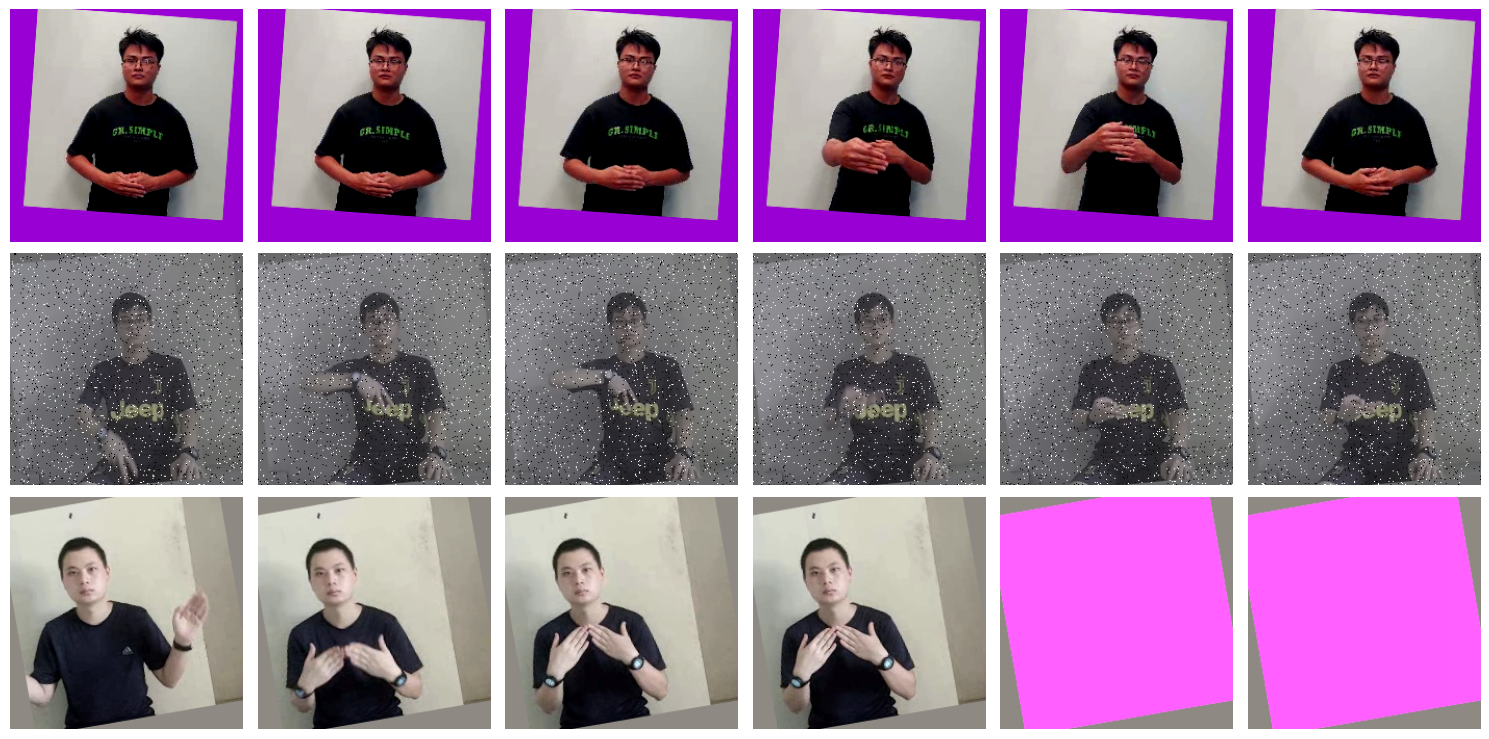

In [7]:
# Look at a few augmented clips before spending GPU hours
import matplotlib.pyplot as plt
fig, axes = plt.subplots(3, 6, figsize=(15, 7.5))
for r in range(3):
    p = df.path.iloc[np.random.randint(len(df))]
    fr = drop_blank(read_video(p))
    fr = augment_clip(fr[sample_idx(len(fr), T, train=True)])
    for c in range(6):
        axes[r, c].imshow(fr[c * 3]); axes[r, c].axis('off')
plt.tight_layout(); plt.show()

## Model

In [8]:
class TemporalHead(nn.Module):
    """Frame features (B,T,1536) -> CLS-token Transformer over time -> logits."""
    def __init__(self, in_dim=1536, d=384, depth=2, heads=6, drop=0.2, n_cls=NUM_CLASSES, t_max=32):
        super().__init__()
        self.inp = nn.Sequential(nn.LayerNorm(in_dim), nn.Dropout(drop), nn.Linear(in_dim, d))
        self.cls = nn.Parameter(torch.zeros(1, 1, d))
        self.pos = nn.Parameter(torch.zeros(1, t_max + 1, d))
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, drop, activation='gelu', batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d)
        self.fc = nn.Linear(d, n_cls)

    def forward(self, x):
        x = self.inp(x)
        x = torch.cat([self.cls.expand(len(x), -1, -1), x], dim=1) + self.pos[:, :x.shape[1] + 1]
        return self.fc(self.norm(self.enc(x)[:, 0]))


class ViTVideo(nn.Module):
    def __init__(self):
        super().__init__()
        self.vit = vit_b_16(weights=WEIGHTS)
        self.vit.heads = nn.Identity()
        self.head = TemporalHead()

    def forward(self, x):  # (B,T,3,224,224)
        B, Tn = x.shape[:2]
        v = self.vit
        z = v._process_input(x.flatten(0, 1))
        z = torch.cat([v.class_token.expand(z.shape[0], -1, -1), z], 1) + v.encoder.pos_embedding
        for blk in v.encoder.layers:
            z = checkpoint(blk, z, use_reentrant=False) if (self.training and GRAD_CKPT) else blk(z)
        z = v.encoder.ln(z)
        f = torch.cat([z[:, 0], z[:, 1:].mean(1)], 1)
        return self.head(f.view(B, Tn, -1).float())


def param_groups(model):
    """Layer-wise LR decay: the top ViT block gets LR_BACKBONE, each block below x LAYER_DECAY."""
    v, L = model.vit, len(model.vit.encoder.layers)
    groups = [{'params': list(model.head.parameters()), 'lr': LR_HEAD},
              {'params': list(v.encoder.ln.parameters()), 'lr': LR_BACKBONE}]
    for i, blk in enumerate(v.encoder.layers):
        groups.append({'params': list(blk.parameters()), 'lr': LR_BACKBONE * LAYER_DECAY ** (L - 1 - i)})
    groups.append({'params': [v.class_token, v.encoder.pos_embedding, *v.conv_proj.parameters()],
                   'lr': LR_BACKBONE * LAYER_DECAY ** L})
    return groups


def cosine_with_warmup(opt, total, warmup):
    return torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (s + 1) / warmup if s < warmup else 0.5 * (1 + math.cos(math.pi * (s - warmup) / max(1, total - warmup))))


def macro_f1(y, logits):
    return f1_score(y, logits.argmax(1), average='macro', labels=np.arange(NUM_CLASSES), zero_division=0)


@torch.no_grad()
def predict(model, paths, phases=(0.5,), desc='predict'):
    """Mean logits over temporal TTA phases."""
    model.eval()
    total = 0
    for ph in phases:
        loader = DataLoader(VideoDataset(paths, phase=ph), batch_size=BATCH * 2, num_workers=NUM_WORKERS)
        out = []
        for x, _ in tqdm(loader, desc=f'{desc} φ={ph}', leave=False):
            with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=DEVICE == 'cuda'):
                out.append(model(x.to(DEVICE, non_blocking=True)).float().cpu())
        total = total + torch.cat(out).numpy()
    return total / len(phases)

## Train (resumes from the last checkpoint on Drive)

In [9]:
model = ViTVideo().to(DEVICE)
opt = torch.optim.AdamW(param_groups(model), weight_decay=WEIGHT_DECAY)
steps_per_epoch = tr_df.group.nunique() // BATCH
sched = cosine_with_warmup(opt, EPOCHS * steps_per_epoch, steps_per_epoch)
scaler = torch.amp.GradScaler('cuda', enabled=DEVICE == 'cuda' and AMP_DTYPE == torch.float16)
crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTH)

ckpt_path = f'{OUT_DIR}/{RUN_NAME}_last.pth'
start_epoch, history = 0, []
if os.path.exists(ckpt_path):
    ck = torch.load(ckpt_path, map_location=DEVICE)
    model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
    scaler.load_state_dict(ck['scaler']); start_epoch, history = ck['epoch'], ck['history']
    print(f'resumed from epoch {start_epoch}')

for ep in range(start_epoch, EPOCHS):
    seed_all(SEED + ep)
    paths, labels = epoch_paths(tr_df)
    loader = DataLoader(VideoDataset(paths, labels, train=True), batch_size=BATCH, shuffle=True, drop_last=True,
                        num_workers=NUM_WORKERS, pin_memory=DEVICE == 'cuda', persistent_workers=False)
    model.train()
    tot, t0 = 0.0, time.time()
    pbar = tqdm(loader, desc=f'epoch {ep + 1}/{EPOCHS}')
    for step, (x, y) in enumerate(pbar, 1):
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE, dtype=AMP_DTYPE, enabled=DEVICE == 'cuda'):
            loss = crit(model(x), y)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        tot += loss.item()
        pbar.set_postfix(loss=f'{tot / step:.4f}')
    rec = {'epoch': ep + 1, 'loss': tot / len(loader), 'min': (time.time() - t0) / 60}
    if len(va_df):
        logits = predict(model, va_df.path.values, desc='val')
        rec['f1'] = macro_f1(va_df.label_idx.values, logits)
        rec['f1_la'] = macro_f1(va_df.label_idx.values, logits - 0.5 * LOG_PRIOR)
        if rec['f1'] >= max([h.get('f1', 0) for h in history], default=0):
            torch.save(model.state_dict(), f'{OUT_DIR}/{RUN_NAME}_best.pth')
    history.append(rec)
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in rec.items()})
    torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                'scaler': scaler.state_dict(), 'epoch': ep + 1, 'history': history}, ckpt_path)

resumed from epoch 6


epoch 7/20:   0%|          | 0/350 [00:00<?, ?it/s]

{'epoch': 7, 'loss': 1.2719, 'min': 8.1377}


epoch 8/20:   0%|          | 0/350 [00:00<?, ?it/s]

{'epoch': 8, 'loss': 1.1762, 'min': 8.3067}


...

{'epoch': 18, 'loss': 0.8469, 'min': 8.6428}


epoch 19/20:   0%|          | 0/350 [00:00<?, ?it/s]

{'epoch': 19, 'loss': 0.8435, 'min': 8.1616}


epoch 20/20:   0%|          | 0/350 [00:00<?, ?it/s]

{'epoch': 20, 'loss': 0.844, 'min': 8.4764}


## Predict test → `cv_submission.zip`

Uses the **last** epoch (val is optimistic, so best-epoch picking on it is not trusted). τ for logit adjustment is tuned on val when there is one, else 0.5 (the value chosen in `ViT.ipynb`).

In [10]:
TTA_PHASES = (0.25, 0.5, 0.75)

TAU = 0.25   # best τ on fold-0 val of the fold-0 run (private 77.50)
if len(va_df):
    va_logits = predict(model, va_df.path.values, TTA_PHASES, desc='val tta')
    taus = np.arange(0, 1.51, 0.25)
    scores = [macro_f1(va_df.label_idx.values, va_logits - t * LOG_PRIOR) for t in taus]
    TAU = float(taus[int(np.argmax(scores))])
    print('val macro-F1 by τ:', dict(zip(taus.round(2), np.round(np.array(scores) * 100, 2))), '-> τ =', TAU)

for split in ['public_test', 'private_test']:
    logits = predict(model, [f'{DATA}/{split}/{f}' for f in test_files[split]], TTA_PHASES, desc=split)
    np.save(f'{OUT_DIR}/logits_{RUN_NAME}_{split}.npy', logits)   # raw logits, for ensembling with ViT.ipynb
    adj = F.log_softmax(torch.from_numpy(logits), 1).numpy() - TAU * LOG_PRIOR
    sub = pd.DataFrame({'video_name': test_files[split], 'label': [idx_to_label[int(p)] for p in adj.argmax(1)]})
    if split == 'private_test':
        csv_path = f'{OUT_DIR}/cv_submission.csv'
        sub.to_csv(csv_path, index=False, encoding='utf-8')
        zip_path = f'{OUT_DIR}/cv_submission_{RUN_NAME}.zip'
        with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
            zf.write(csv_path, arcname='cv_submission.csv')   # csv at the zip root, as required
        print(f'{zip_path}: {len(sub)} rows, {sub.label.nunique()} distinct labels, top {sub.label.value_counts().head(3).to_dict()}')

public_test φ=0.25:   0%|          | 0/102 [00:00<?, ?it/s]

public_test φ=0.5:   0%|          | 0/102 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ed440507420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ed440507420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

public_test φ=0.75:   0%|          | 0/102 [00:00<?, ?it/s]

private_test φ=0.25:   0%|          | 0/179 [00:00<?, ?it/s]

private_test φ=0.5:   0%|          | 0/179 [00:00<?, ?it/s]

private_test φ=0.75:   0%|          | 0/179 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ed440507420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7ed440507420>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

/content/drive/MyDrive/sign-language/cv_submission_vitb16_ft_full.zip: 2859 rows, 100 distinct labels, top {'Biếu tặng': 71, 'Giúp': 52, 'Biết': 49}


Bring the results back without Drive: the bundle below is printed as base64 into this notebook's output, which VS Code saves to the local `.ipynb` (save the notebook after this cell runs).

In [11]:
import base64, io
buf = io.BytesIO()
with zipfile.ZipFile(buf, 'w', zipfile.ZIP_DEFLATED) as zf:
    zf.write(zip_path, arcname=os.path.basename(zip_path))
    for split in ['public_test', 'private_test']:
        logits = np.load(f'{OUT_DIR}/logits_{RUN_NAME}_{split}.npy').astype(np.float16)
        b = io.BytesIO(); np.save(b, logits)
        zf.writestr(f'logits_{RUN_NAME}_{split}.npy', b.getvalue())
    zf.writestr('history.json', __import__('json').dumps(history))
payload = base64.b64encode(buf.getvalue()).decode()
print(f'BUNDLE_BEGIN {RUN_NAME} {len(payload)}')
print(payload)
print('BUNDLE_END')

BUNDLE_BEGIN vitb16_ft_full 1132196
...
BUNDLE_END
